# Structural Inequality in Olympic Competition: Reproducible Analysis

This notebook regenerates every figure, table and headline number in the paper from the raw data, top to bottom.

**Data (put these files in `DATA_DIR`):**
- `athlete_events.csv` and `noc_regions.csv`: the "120 Years of Olympic History" dataset (Kaggle, `heesoo37/120-years-of-olympic-history-athletes-and-results`; also mirrored at `github.com/rgriff23/Olympic_history/tree/master/data`).
- `gdp.csv` and `population.csv`: World Bank World Development Indicators (GDP in current US$, total population), mirrored at `github.com/datasets/gdp` and `github.com/datasets/population`.

**Conventions used throughout**
- A *record* (or entry) is one row of `athlete_events.csv`: one athlete in one event at one Games.
- *Athlete-level medals* count every medal row, so each member of a medal-winning team counts once.
- *Medal-table medals* count one medal per NOC per event per medal type, as in an official medal table.
- Figures are saved to `figures/` at 300 dpi.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import squarify
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold

warnings.filterwarnings("ignore")
DATA_DIR = os.environ.get("OLYMPIC_DATA", "data")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
# Figure style follows the IEEE Access template:
# - every figure is drawn at its printed size: one column (3.35 in) or the full text width (6.97 in),
#   so all text prints at exactly the same 8 pt size in every figure;
# - text in Arial (Liberation Sans is the metric-identical fallback when Arial is not installed);
# - subfigure labels (a), (b), (c) centred below each panel in 8 pt Times New Roman (fallback Liberation Serif);
# - no titles or captions inside the figure (the caption goes in the manuscript); 300 dpi for colour figures.
COL_W, PAGE_W = 3.35, 6.97
PT = 8
ANNOT = PT
SANS = ["Arial", "Helvetica", "Liberation Sans"]
SERIF = ["Times New Roman", "Liberation Serif"]
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": SANS, "font.size": PT,
                     "axes.titlesize": PT, "axes.labelsize": PT, "xtick.labelsize": PT, "ytick.labelsize": PT,
                     "legend.fontsize": PT, "figure.titlesize": PT, "legend.title_fontsize": PT,
                     "lines.linewidth": 1.2, "lines.markersize": 3, "legend.handlelength": 1.6,
                     "legend.borderaxespad": 0.3, "legend.columnspacing": 1.0, "legend.handletextpad": 0.4,
                     "figure.constrained_layout.use": True, "figure.dpi": 100, "savefig.dpi": 300,
                     "axes.grid": True, "grid.alpha": 0.3, "grid.linewidth": 0.5, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
RESULTS = {}  # every number quoted in the paper is collected here


def save(fig, name):
    """Save at the exact printed size (no tight cropping, so the width stays 3.35 in or 6.97 in)."""
    fig.savefig(os.path.join(FIG_DIR, name))
    plt.show()


def panels(n, height, width_ratios=None):
    """Multipart figure at full text width: n subfigures, each with one axes and an (a), (b), ... label
    centred below it in 8 pt Times New Roman, as the IEEE Access template requires."""
    fig = plt.figure(figsize=(PAGE_W, height))
    subs = fig.subfigures(1, n, wspace=0.02, width_ratios=width_ratios)
    axes = []
    for i, sf in enumerate(np.atleast_1d(subs)):
        axes.append(sf.subplots())
        sf.supxlabel(f"({'abcdefgh'[i]})", fontfamily=SERIF, fontsize=PT)
    return fig, axes

In [2]:
ath = pd.read_csv(os.path.join(DATA_DIR, "athlete_events.csv"))
noc_regions = pd.read_csv(os.path.join(DATA_DIR, "noc_regions.csv"))
gdp_raw = pd.read_csv(os.path.join(DATA_DIR, "gdp.csv"))
pop_raw = pd.read_csv(os.path.join(DATA_DIR, "population.csv"))
summer = ath[ath.Season == "Summer"].copy()

RESULTS["records_total"] = len(ath)
RESULTS["years"] = (int(ath.Year.min()), int(ath.Year.max()))
print(f"{len(ath):,} athlete-event records, {ath.Year.min()}-{ath.Year.max()}; "
      f"{len(summer):,} Summer records from {summer.Games.nunique()} Summer Games")

271,116 athlete-event records, 1896-2016; 222,552 Summer records from 29 Summer Games


## 1. Athlete archetypes (k-means clustering)

Male Summer competitors with complete height, weight and age. Each athlete is kept once per Games
(an athlete entered in several events at the same Games is one physical observation), so multi-event
athletes such as swimmers are not over-weighted. Features are standardized before k-means.

Clustering sample: 85,383 athlete-Games observations (59,482 distinct athletes)


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (20 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


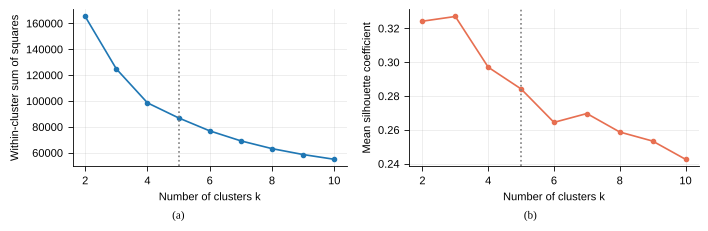

In [3]:
men = summer[summer.Sex == "M"].dropna(subset=["Height", "Weight", "Age"])
men = men.drop_duplicates(["ID", "Games"]).copy()
FEATS = ["Height", "Weight", "Age"]
X = StandardScaler().fit_transform(men[FEATS])
RESULTS["cluster_n"] = len(men)
print(f"Clustering sample: {len(men):,} athlete-Games observations "
      f"({men.ID.nunique():,} distinct athletes)")

rng = np.random.RandomState(42)
sil_idx = rng.choice(len(X), 20000, replace=False)  # silhouette on a fixed random sample for speed
ks, inertia, sil = range(2, 11), [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X[sil_idx], km.labels_[sil_idx]))
sel = pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil})
print(sel.round(3).to_string(index=False))

fig, ax = panels(2, 2.2)
ax[0].plot(sel.k, sel.inertia, "o-"); ax[0].set_xlabel("Number of clusters k"); ax[0].set_ylabel("Within-cluster sum of squares")
ax[1].plot(sel.k, sel.silhouette, "o-", color="#e76f51"); ax[1].set_xlabel("Number of clusters k"); ax[1].set_ylabel("Mean silhouette coefficient")
for a in ax: a.axvline(5, ls=":", color="grey")
save(fig, "supp_cluster_selection.png")

In [4]:
K = 5
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X)
men["cluster"] = km.labels_
RESULTS["silhouette_k5"] = float(sel.set_index("k").silhouette[K])

# Name clusters from their centroids (data-driven, so names stay stable if the code is rerun)
cent = men.groupby("cluster")[FEATS].mean()
names = {}
names[cent.Age.idxmax()] = "Veteran"                       # oldest cluster
rest = cent.drop(list(names))
names[rest.Weight.idxmax()] = "Heavyweight"                 # heaviest of the rest
rest = rest.drop(list(names), errors="ignore")
names[rest.Height.idxmin()] = "Compact"                     # shortest of the rest
rest = rest.drop(list(names), errors="ignore")
names[rest.Age.idxmin()] = "Lean"                           # younger of the two remaining
names[rest.drop(list(names), errors="ignore").index[0]] = "Mid-career"
men["archetype"] = men.cluster.map(names)
ORDER = ["Lean", "Compact", "Mid-career", "Heavyweight", "Veteran"]
# Colors follow the original figures: blue (endurance-like Lean), green (agility-like Compact),
# orange (power-like Heavyweight), gold (technical-like Veteran), red (Mid-career)
COLORS = {"Lean": "#1E88E5", "Compact": "#43A047", "Mid-career": "#E53935", "Heavyweight": "#FB8C00", "Veteran": "#E6B800"}
# Unique marker + line style per archetype so the figures do not rely on color alone (greyscale / CVD readable)
MARK = {"Lean": "o", "Compact": "s", "Mid-career": "^", "Heavyweight": "D", "Veteran": "v"}
DASH = {"Lean": "-", "Compact": "--", "Mid-career": "-.", "Heavyweight": ":", "Veteran": (0, (5, 1, 1, 1, 1, 1))}
# Generic style cycle for other multi-series line charts
STYLES = [("o", "-"), ("s", "--"), ("^", "-."), ("D", ":"), ("v", (0, (5, 1, 1, 1, 1, 1))), ("P", "-"), ("X", "--"), ("*", "-.")]


def signature_sports(group, n=3, min_count=200):
    """Sports most over-represented in a cluster relative to the full sample (lift), among sports with min_count entries."""
    share_all = men.Sport.value_counts(normalize=True)
    share_c = group.Sport.value_counts(normalize=True)
    counts = group.Sport.value_counts()
    lift = (share_c / share_all).dropna()
    lift = lift[counts.reindex(lift.index).fillna(0) >= min_count]
    return ", ".join(lift.sort_values(ascending=False).head(n).index)


table1 = (men.groupby("archetype")
          .agg(share=("ID", lambda s: len(s) / len(men) * 100), height=("Height", "mean"),
               weight=("Weight", "mean"), age=("Age", "mean"))
          .reindex(ORDER))
table1["signature_sports"] = [signature_sports(men[men.archetype == a]) for a in ORDER]
RESULTS["table1"] = table1.round(1).reset_index().to_dict("records")
print(f"Mean silhouette at k=5: {RESULTS['silhouette_k5']:.3f}")
table1.round(1)

Mean silhouette at k=5: 0.284


,share,height,weight,age,signature_sports
archetype,,,,,
Lean,31.6,182.7,77.6,22.4,"Swimming, Football, Canoeing"
Compact,23.4,168.3,62.2,23.6,"Gymnastics, Diving, Boxing"
Mid-career,21.5,178.6,74.7,29.6,"Modern Pentathlon, Badminton, Fencing"
Heavyweight,18.3,192.8,98.2,26.5,"Beach Volleyball, Basketball, Volleyball"
Veteran,5.2,176.4,76.7,40.9,"Equestrianism, Shooting, Sailing"


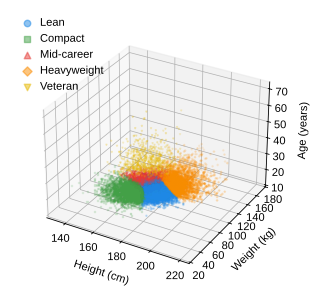

In [5]:
# Figure 1: 3D view of the clusters (random sample of 15,000 points for legibility)
samp = men.sample(15000, random_state=1)
fig = plt.figure(figsize=(COL_W, 3.2), layout=None)
ax = fig.add_axes([0.0, 0.02, 0.86, 0.98], projection="3d")
for a in ORDER:
    s = samp[samp.archetype == a]
    ax.scatter(s.Height, s.Weight, s.Age, s=0.6, alpha=0.5, color=COLORS[a], marker=MARK[a], label=a, rasterized=True)
ax.set_xlabel("Height (cm)", labelpad=-2); ax.set_ylabel("Weight (kg)", labelpad=-2); ax.set_zlabel("Age (years)", labelpad=-3)
ax.tick_params(pad=-2)
ax.set_box_aspect(None, zoom=0.88)
ax.legend(markerscale=6, loc="upper left", bbox_to_anchor=(0.0, 1.0), frameon=False)
save(fig, "sarav1.png")

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (32 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


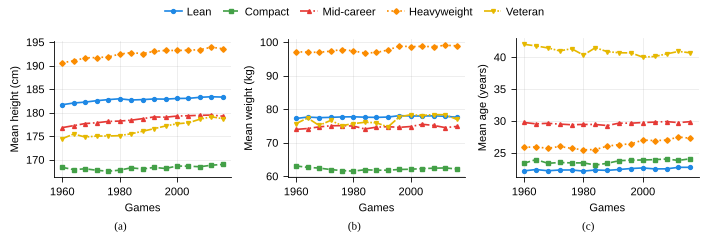

Fitted spread between archetypes, 1960 -> 2016:
  height: 23.3 cm -> 25.3 cm
  weight: 34.5 kg -> 36.9 kg


,Height,Weight,Age
Lean,0.24,0.09,0.09
Compact,0.18,-0.04,0.11
Mid-career,0.46,0.10,0.06
Heavyweight,0.53,0.40,0.32
Veteran,0.85,0.44,-0.24


In [6]:
# Figure 2: archetype means per Games, 1960-2016 (linear fits are used only for the fitted 1960 and 2016 values quoted in the paper)
mod = men[men.Year >= 1960]
means = mod.groupby(["archetype", "Year"])[FEATS].mean().reset_index()
fits = {}
fig, axes = panels(3, 2.3)
for ax, f, unit in zip(axes, FEATS, ["cm", "kg", "years"]):
    for a in ORDER:
        m = means[means.archetype == a]
        lr = LinearRegression().fit(m[["Year"]], m[f])
        fits[(a, f)] = lr
        ax.plot(m.Year, m[f], marker=MARK[a], ls=DASH[a], ms=2.8, lw=1.2, color=COLORS[a], label=a)  # observed means; fits feed the text only
    ax.set_ylabel(f"Mean {f.lower()} ({unit})"); ax.set_xlabel("Games")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=5, frameon=False)
save(fig, "sarav2.png")

fitted = {(a, f, y): float(fits[(a, f)].predict(pd.DataFrame({"Year": [y]}))[0]) for a in ORDER for f in FEATS for y in (1960, 2016)}
h60 = [fitted[(a, "Height", 1960)] for a in ORDER]; h16 = [fitted[(a, "Height", 2016)] for a in ORDER]
w60 = [fitted[(a, "Weight", 1960)] for a in ORDER]; w16 = [fitted[(a, "Weight", 2016)] for a in ORDER]
RESULTS["height_range_1960_2016"] = (max(h60) - min(h60), max(h16) - min(h16))
RESULTS["weight_range_1960_2016"] = (max(w60) - min(w60), max(w16) - min(w16))
RESULTS["trend_per_decade"] = {a: {f: fits[(a, f)].coef_[0] * 10 for f in FEATS} for a in ORDER}
print("Fitted spread between archetypes, 1960 -> 2016:")
print(f"  height: {RESULTS['height_range_1960_2016'][0]:.1f} cm -> {RESULTS['height_range_1960_2016'][1]:.1f} cm")
print(f"  weight: {RESULTS['weight_range_1960_2016'][0]:.1f} kg -> {RESULTS['weight_range_1960_2016'][1]:.1f} kg")
pd.DataFrame(RESULTS["trend_per_decade"]).T.round(2)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (32 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


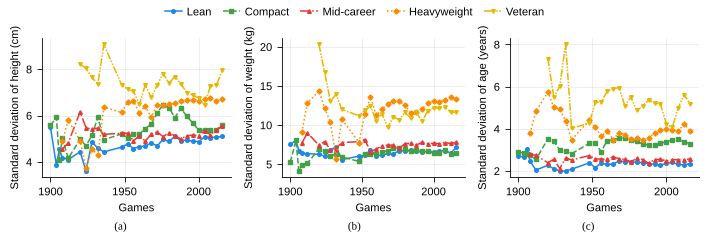

Fitted change in within-archetype SD, 1960-2016:


,Height,Weight,Age
Lean,0.39,0.60,-0.07
Compact,-0.31,-0.24,-0.13
Mid-career,0.29,0.61,-0.05
Heavyweight,0.58,1.33,0.41
Veteran,0.21,1.53,-0.88


In [7]:
# Figure 3: within-archetype standard deviation per Games (Games with more than 10 athletes in the archetype)
sd = (men.groupby(["archetype", "Year"]).filter(lambda g: len(g) > 10)
      .groupby(["archetype", "Year"])[FEATS].std().reset_index())
fig, axes = panels(3, 2.3)
for ax, f, unit in zip(axes, FEATS, ["cm", "kg", "years"]):
    for a in ORDER:
        s = sd[sd.archetype == a]
        ax.plot(s.Year, s[f], marker=MARK[a], ls=DASH[a], ms=2.6, lw=1.1, color=COLORS[a], label=a)
    ax.set_ylabel(f"Standard deviation of {f.lower()} ({unit})"); ax.set_xlabel("Games")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=5, frameon=False)
save(fig, "sarav3.png")

sd_mod = sd[sd.Year >= 1960]
sd_trend = {}
for a in ORDER:
    s = sd_mod[sd_mod.archetype == a]
    sd_trend[a] = {f: LinearRegression().fit(s[["Year"]], s[f]).coef_[0] * 56 for f in FEATS}  # fitted change 1960-2016
RESULTS["sd_change_1960_2016"] = sd_trend
print("Fitted change in within-archetype SD, 1960-2016:")
pd.DataFrame(sd_trend).T.round(2)

## 2. Sport composition of the Games
Share of each Summer Games' distinct athletes competing in each sport, with a linear trend fitted to
1960-2016 and extended to 2028. Distinct athletes (not athlete-event records) are used so that sports with
many events per athlete, such as gymnastics and swimming, are not over-counted.

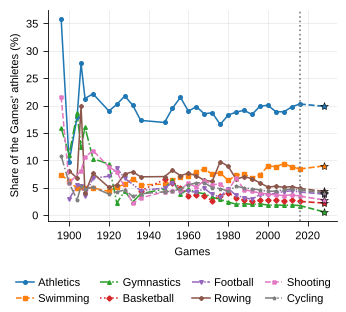

      sports  events  athletes
Year                          
1896       9      43       176
1912      17     107      2409
1948      20     153      4402
1960      19     150      5352
1988      27     237      8454
2016      34     306     11179
{
 "athletics_share": {
  "1896_1948_min": 9.722222222222223,
  "1896_1948_max": 35.79545454545455,
  "max_year": 1896,
  "2016": 20.296985419089363,
  "2028_proj": 19.885084073520797
 },
 "swimming_2016": 8.42651399946328,
 "gymnastics": {
  "peak": 18.615384615384613,
  "peak_year": 1904,
  "2016": 1.7532874139010644
 }
}


In [8]:
share = (summer.groupby(["Year", "Sport"]).ID.nunique() / summer.groupby("Year").ID.nunique() * 100).rename("pct").reset_index()
SPORTS = ["Athletics", "Swimming", "Gymnastics", "Basketball", "Football", "Rowing", "Shooting", "Cycling"]
fig, ax = plt.subplots(figsize=(COL_W, 3.0))
proj = {}
for (mk, ls), sp in zip(STYLES, SPORTS):
    s = share[share.Sport == sp]
    line, = ax.plot(s.Year, s.pct, marker=mk, ls=ls, ms=2.6, lw=1.1, label=sp)
    m = s[s.Year >= 1960]
    lr = LinearRegression().fit(m[["Year"]], m.pct)
    p = max(0.0, float(lr.predict(pd.DataFrame({"Year": [2028]}))[0]))
    proj[sp] = p
    ax.plot([2016, 2028], [s[s.Year == 2016].pct.iloc[0], p], "--", color=line.get_color())
    ax.plot(2028, p, "*", ms=6, color=line.get_color(), mec="black", mew=0.4)
ax.axvline(2016, ls=":", color="grey")
ax.set_xlabel("Games"); ax.set_ylabel("Share of the Games' athletes (%)")
fig.legend(loc="outside lower center", ncol=4, frameon=False)
save(fig, "sarav4.png")

ath_sh = share[share.Sport == "Athletics"].set_index("Year").pct
gym_sh = share[share.Sport == "Gymnastics"].set_index("Year").pct
swim_sh = share[share.Sport == "Swimming"].set_index("Year").pct
RESULTS["athletics_share"] = {"1896_1948_min": ath_sh.loc[:1948].min(), "1896_1948_max": ath_sh.loc[:1948].max(),
                              "max_year": int(ath_sh.loc[:1948].idxmax()), "2016": ath_sh[2016], "2028_proj": proj["Athletics"]}
RESULTS["swimming_2016"] = swim_sh[2016]
RESULTS["gymnastics"] = {"peak": gym_sh.max(), "peak_year": int(gym_sh.idxmax()), "2016": gym_sh[2016]}
RESULTS["sport_2016"] = share[share.Year == 2016].set_index("Sport").pct.reindex(SPORTS).round(1).to_dict()
RESULTS["sport_2028_proj"] = {k: round(v, 1) for k, v in proj.items()}
RESULTS["athletics_by_year"] = ath_sh.round(1).to_dict()
size = summer.groupby("Year").agg(sports=("Sport", "nunique"), events=("Event", "nunique"), athletes=("ID", "nunique"))
RESULTS["games_size"] = {int(y): r for y, r in size.loc[[1896, 1912, 1948, 1960, 1988, 2016]].to_dict("index").items()}
print(size.loc[[1896, 1912, 1948, 1960, 1988, 2016]])
print(json.dumps({k: RESULTS[k] for k in ["athletics_share", "swimming_2016", "gymnastics"]}, indent=1, default=float))

## 3. Participation by continent
Distinct athletes per Summer Games, grouped by the continent of their NOC (via `noc_regions.csv`).

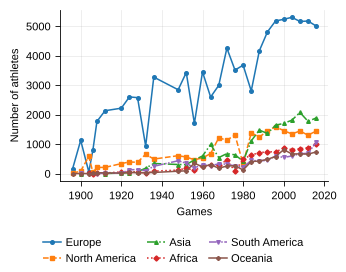

Unmapped NOCs: ['IOA', 'ROT', 'SGP', 'TUV', 'UNK']


{'europe_peak': 5303.0,
 'europe_peak_year': 2004,
 'europe_2016': 5006.0,
 'asia_2016': 1889.0,
 'namerica_2016': 1448.0,
 'africa_2016': 990.0,
 'samerica_2016': 1065.0}

In [9]:
CONTINENTS = {
    'Afghanistan': 'Asia', 'Albania': 'Europe', 'Algeria': 'Africa', 'American Samoa': 'Oceania',
    'Andorra': 'Europe', 'Angola': 'Africa', 'Antigua': 'North America', 'Antigua and Barbuda': 'North America',
    'Argentina': 'South America', 'Armenia': 'Europe', 'Aruba': 'North America', 'Australia': 'Oceania',
    'Austria': 'Europe', 'Azerbaijan': 'Europe', 'Bahamas': 'North America', 'Bahrain': 'Asia',
    'Bangladesh': 'Asia', 'Barbados': 'North America', 'Belarus': 'Europe', 'Belgium': 'Europe',
    'Belize': 'North America', 'Benin': 'Africa', 'Bermuda': 'North America', 'Bhutan': 'Asia',
    'Boliva': 'South America', 'Bolivia': 'South America', 'Bosnia and Herzegovina': 'Europe', 'Botswana': 'Africa',
    'Brazil': 'South America', 'Brunei': 'Asia', 'Bulgaria': 'Europe', 'Burkina Faso': 'Africa',
    'Burundi': 'Africa', 'Cambodia': 'Asia', 'Cameroon': 'Africa', 'Canada': 'North America',
    'Cape Verde': 'Africa', 'Cayman Islands': 'North America', 'Central African Republic': 'Africa', 'Chad': 'Africa',
    'Chile': 'South America', 'China': 'Asia', 'Chinese Taipei': 'Asia', 'Colombia': 'South America',
    'Comoros': 'Africa', 'Congo': 'Africa', 'Cook Islands': 'Oceania', 'Costa Rica': 'North America',
    'Croatia': 'Europe', 'Cuba': 'North America', 'Curacao': 'North America', 'Cyprus': 'Europe',
    'Czech Republic': 'Europe', 'Czechia': 'Europe', 'Czechoslovakia': 'Europe', 'Democratic Republic of the Congo': 'Africa',
    'Denmark': 'Europe', 'Djibouti': 'Africa', 'Dominica': 'North America', 'Dominican Republic': 'North America',
    'East Germany': 'Europe', 'Ecuador': 'South America', 'Egypt': 'Africa', 'El Salvador': 'North America',
    'Equatorial Guinea': 'Africa', 'Eritrea': 'Africa', 'Estonia': 'Europe', 'Eswatini': 'Africa',
    'Ethiopia': 'Africa', 'Fiji': 'Oceania', 'Finland': 'Europe', 'France': 'Europe',
    'Gabon': 'Africa', 'Gambia': 'Africa', 'Georgia': 'Europe', 'Germany': 'Europe',
    'Ghana': 'Africa', 'Great Britain': 'Europe', 'Greece': 'Europe', 'Grenada': 'North America',
    'Guam': 'Oceania', 'Guatemala': 'North America', 'Guinea': 'Africa', 'Guinea-Bissau': 'Africa',
    'Guyana': 'South America', 'Haiti': 'North America', 'Honduras': 'North America', 'Hong Kong': 'Asia',
    'Hungary': 'Europe', 'Iceland': 'Europe', 'India': 'Asia', 'Indonesia': 'Asia',
    'Iran': 'Asia', 'Iraq': 'Asia', 'Ireland': 'Europe', 'Israel': 'Asia',
    'Italy': 'Europe', 'Ivory Coast': 'Africa', 'Jamaica': 'North America', 'Japan': 'Asia',
    'Jordan': 'Asia', 'Kazakhstan': 'Asia', 'Kenya': 'Africa', 'Kiribati': 'Oceania',
    'Korea': 'Asia', 'Kosovo': 'Europe', 'Kuwait': 'Asia', 'Kyrgyzstan': 'Asia',
    'Laos': 'Asia', 'Latvia': 'Europe', 'Lebanon': 'Asia', 'Lesotho': 'Africa',
    'Liberia': 'Africa', 'Libya': 'Africa', 'Liechtenstein': 'Europe', 'Lithuania': 'Europe',
    'Luxembourg': 'Europe', 'Macedonia': 'Europe', 'Madagascar': 'Africa', 'Malawi': 'Africa',
    'Malaysia': 'Asia', 'Maldives': 'Asia', 'Mali': 'Africa', 'Malta': 'Europe',
    'Marshall Islands': 'Oceania', 'Mauritania': 'Africa', 'Mauritius': 'Africa', 'Mexico': 'North America',
    'Micronesia': 'Oceania', 'Moldova': 'Europe', 'Monaco': 'Europe', 'Mongolia': 'Asia',
    'Montenegro': 'Europe', 'Morocco': 'Africa', 'Mozambique': 'Africa', 'Myanmar': 'Asia',
    'Namibia': 'Africa', 'Nauru': 'Oceania', 'Nepal': 'Asia', 'Netherlands': 'Europe',
    'New Zealand': 'Oceania', 'Nicaragua': 'North America', 'Niger': 'Africa', 'Nigeria': 'Africa',
    'North Korea': 'Asia', 'North Macedonia': 'Europe', 'Norway': 'Europe', 'Olympic Athletes from Russia': 'Europe',
    'Oman': 'Asia', 'Pakistan': 'Asia', 'Palau': 'Oceania', 'Palestine': 'Asia',
    'Panama': 'North America', 'Papua New Guinea': 'Oceania', 'Paraguay': 'South America', 'Peru': 'South America',
    'Philippines': 'Asia', 'Poland': 'Europe', 'Portugal': 'Europe', 'Puerto Rico': 'North America',
    'Qatar': 'Asia', 'ROC': 'Europe', 'Republic of Congo': 'Africa', 'Romania': 'Europe',
    'Russia': 'Europe', 'Russian Federation': 'Europe', 'Rwanda': 'Africa', 'Saint Kitts': 'North America',
    'Saint Kitts and Nevis': 'North America', 'Saint Lucia': 'North America', 'Saint Vincent': 'North America', 'Saint Vincent and the Grenadines': 'North America',
    'Samoa': 'Oceania', 'San Marino': 'Europe', 'Sao Tome and Principe': 'Africa', 'Saudi Arabia': 'Asia',
    'Senegal': 'Africa', 'Serbia': 'Europe', 'Serbia and Montenegro': 'Europe', 'Seychelles': 'Africa',
    'Sierra Leone': 'Africa', 'Singapore': 'Asia', 'Slovakia': 'Europe', 'Slovenia': 'Europe',
    'Solomon Islands': 'Oceania', 'Somalia': 'Africa', 'South Africa': 'Africa', 'South Korea': 'Asia',
    'South Sudan': 'Africa', 'Soviet Union': 'Europe', 'Spain': 'Europe', 'Sri Lanka': 'Asia',
    'Sudan': 'Africa', 'Suriname': 'South America', 'Swaziland': 'Africa', 'Sweden': 'Europe',
    'Switzerland': 'Europe', 'Syria': 'Asia', 'Taiwan': 'Asia', 'Tajikistan': 'Asia',
    'Tanzania': 'Africa', 'Thailand': 'Asia', 'Timor-Leste': 'Asia', 'Togo': 'Africa',
    'Tonga': 'Oceania', 'Trinidad': 'North America', 'Trinidad and Tobago': 'North America', 'Tunisia': 'Africa',
    'Turkey': 'Europe', 'Turkmenistan': 'Asia', 'Tuvalu': 'Oceania', 'UK': 'Europe',
    'USA': 'North America', 'USSR': 'Europe', 'Uganda': 'Africa', 'Ukraine': 'Europe',
    'Unified Team': 'Europe', 'United Arab Emirates': 'Asia', 'United Kingdom': 'Europe', 'United States': 'North America',
    'Uruguay': 'South America', 'Uzbekistan': 'Asia', 'Vanuatu': 'Oceania', 'Vatican City': 'Europe',
    'Venezuela': 'South America', 'Vietnam': 'Asia', 'Virgin Islands, British': 'North America', 'Virgin Islands, US': 'North America',
    'West Germany': 'Europe', 'Yemen': 'Asia', 'Yugoslavia': 'Europe', 'Zambia': 'Africa',
    'Zimbabwe': 'Africa',
}
reg = noc_regions.set_index("NOC").region
summer["continent"] = summer.NOC.map(reg).map(CONTINENTS)
cont = summer.dropna(subset=["continent"]).groupby(["Year", "continent"]).ID.nunique().unstack()
fig, ax = plt.subplots(figsize=(COL_W, 2.6))
for (mk, ls), c in zip(STYLES, ["Europe", "North America", "Asia", "Africa", "South America", "Oceania"]):
    ax.plot(cont.index, cont[c], marker=mk, ls=ls, ms=2.6, lw=1.1, label=c)
ax.set_xlabel("Games"); ax.set_ylabel("Number of athletes")
fig.legend(loc="outside lower center", frameon=False, ncol=3)
save(fig, "sarav5.png")
RESULTS["continents"] = {"europe_peak": float(cont.Europe.max()), "europe_peak_year": int(cont.Europe.idxmax()),
                         "europe_2016": float(cont.Europe[2016]), "asia_2016": float(cont.Asia[2016]),
                         "namerica_2016": float(cont["North America"][2016]), "africa_2016": float(cont.Africa[2016]),
                         "samerica_2016": float(cont["South America"][2016])}
print(f"Unmapped NOCs: {sorted(summer[summer.continent.isna()].NOC.unique())}")
RESULTS["continents"]

## 4. Medal inequality: Lorenz curves and Gini coefficients
Main specification: athlete-level medal counts among the NOCs that won at least one medal at each Summer Games.
Robustness: (a) including every participating NOC, zeros included; (b) medal-table counts.

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (18 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


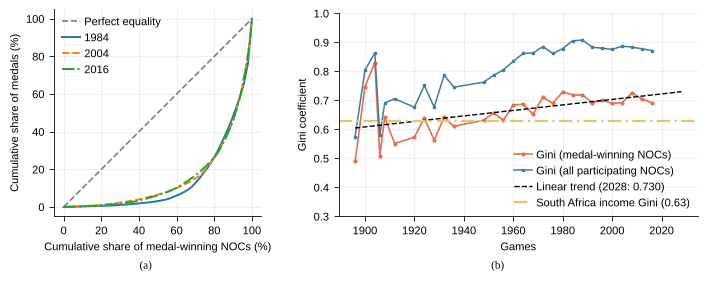

{
 "2016": 0.6915989377967329,
 "2016_all_nocs": 0.8718720224662756,
 "2016_table": 0.6353521833695834,
 "1950s_mean": 0.6441043132319269,
 "1960_2016_min": 0.6525974025974026,
 "2028_trend": 0.7299006033784339,
 "nocs_2016": 207,
 "medal_nocs_2016": 86,
 "top16_share_2016": 0.717745921898171,
 "top16_pct_of_medal_nocs": 0.18604651162790697,
 "bottom80_share_2016": 0.2535837864557588,
 "all_nocs_min_since_1960": 0.8347315874758245
}


,gini,gini_all_nocs,gini_table,medal_nocs,nocs
Year,,,,,
1956,0.632,0.806,0.650,38,72
1984,0.719,0.906,0.693,47,140
2004,0.692,0.887,0.614,74,201
2012,0.705,0.878,0.653,85,205
2016,0.692,0.872,0.635,86,207


In [10]:
def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); c = np.cumsum(x)
    return (n + 1 - 2 * c.sum() / c[-1]) / n


def lorenz(x):
    x = np.sort(np.asarray(x, float)); c = np.cumsum(x) / x.sum() * 100
    return np.insert(np.arange(1, len(x) + 1) / len(x) * 100, 0, 0), np.insert(c, 0, 0)


rows = []
for y, g in summer.groupby("Year"):
    won = g.dropna(subset=["Medal"])
    a = won.groupby("NOC").size()
    t = won.drop_duplicates(["NOC", "Event", "Medal"]).groupby("NOC").size()
    rows.append(dict(Year=y, gini=gini(a), gini_all_nocs=gini(a.reindex(g.NOC.unique()).fillna(0)),
                     gini_table=gini(t), medal_nocs=len(a), nocs=g.NOC.nunique()))
gini_df = pd.DataFrame(rows).set_index("Year")
trend = LinearRegression().fit(gini_df.index.values.reshape(-1, 1), gini_df.gini)
g2028 = float(trend.predict([[2028]])[0])

SA_GINI = 0.63  # South Africa, World Bank: highest national income Gini in its data
fig, axes = panels(2, 2.7, width_ratios=[1, 1.45])
axes[0].plot([0, 100], [0, 100], "--", color="grey", label="Perfect equality")
for y, ls in zip([1984, 2004, 2016], ["-", "--", "-."]):
    g = summer[(summer.Year == y)].dropna(subset=["Medal"]).groupby("NOC").size()
    xs, ys = lorenz(g)
    axes[0].plot(xs, ys, ls=ls, lw=1.4, label=str(y))
axes[0].set_xlabel("Cumulative share of medal-winning NOCs (%)"); axes[0].set_ylabel("Cumulative share of medals (%)")
axes[0].legend(loc="upper left", frameon=False); axes[0].set_aspect("equal")
axes[1].plot(gini_df.index, gini_df.gini, "-o", ms=2, color="#e76f51", label="Gini (medal-winning NOCs)")
axes[1].plot(gini_df.index, gini_df.gini_all_nocs, "-s", ms=2, lw=1.1, color="#457b9d", label="Gini (all participating NOCs)")
xx = np.array([1896, 2028])
axes[1].plot(xx, trend.predict(xx.reshape(-1, 1)), "--", color="black", lw=1, label=f"Linear trend (2028: {g2028:.3f})")
axes[1].axhline(SA_GINI, color="#e9c46a", lw=1.6, ls=(0, (6, 2, 1, 2)), label="South Africa income Gini (0.63)")
axes[1].set_ylim(0.3, 1); axes[1].set_xlabel("Games"); axes[1].set_ylabel("Gini coefficient")
axes[1].legend(loc="lower right", frameon=False)
save(fig, "sarav6.png")

g16 = summer[summer.Year == 2016].dropna(subset=["Medal"]).groupby("NOC").size().sort_values(ascending=False)
srt = np.sort(g16.values)
RESULTS["gini"] = {"2016": gini_df.gini[2016], "2016_all_nocs": gini_df.gini_all_nocs[2016],
                   "2016_table": gini_df.gini_table[2016], "1950s_mean": gini_df.gini.loc[1950:1959].mean(),
                   "1960_2016_min": gini_df.gini.loc[1960:].min(), "2028_trend": g2028,
                   "nocs_2016": int(gini_df.nocs[2016]), "medal_nocs_2016": int(gini_df.medal_nocs[2016]),
                   "top16_share_2016": g16.head(16).sum() / g16.sum(), "top16_pct_of_medal_nocs": 16 / len(g16),
                   "bottom80_share_2016": srt[: int(0.8 * len(srt))].sum() / srt.sum(),
                   "all_nocs_min_since_1960": gini_df.gini_all_nocs.loc[1960:].min()}
print(json.dumps(RESULTS["gini"], indent=1, default=float))
gini_df.loc[[1956, 1984, 2004, 2012, 2016]].round(3)

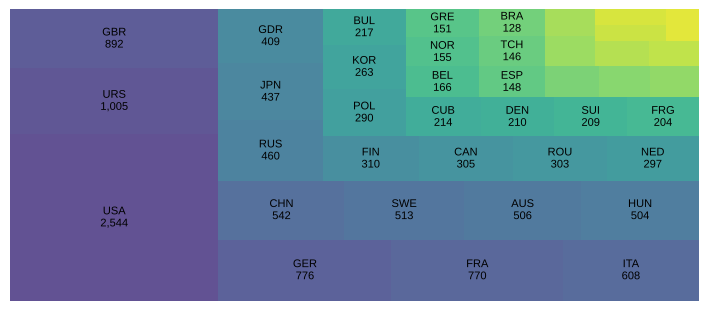

USA + next NOC share of all Summer medals: 22.1% (USA, URS)


In [11]:
# Figure 7: treemap of medal-table medals by NOC, all Summer Games 1896-2016
tm = (summer.dropna(subset=["Medal"]).drop_duplicates(["Games", "NOC", "Event", "Medal"])
      .groupby("NOC").size().sort_values(ascending=False))
top = tm.head(40)
fig, ax = plt.subplots(figsize=(PAGE_W, 3.0))
labels = [f"{n}\n{v:,}" if i < 30 else "" for i, (n, v) in enumerate(top.items())]
squarify.plot(sizes=top.values, label=labels, ax=ax, pad=False, text_kwargs={"fontsize": ANNOT},
              color=plt.cm.viridis(np.linspace(0.15, 0.95, len(top))), alpha=0.85)
ax.axis("off")
save(fig, "sarav7.png")
RESULTS["treemap_top2_share"] = float(tm.head(2).sum() / tm.sum())
print(f"USA + next NOC share of all Summer medals: {RESULTS['treemap_top2_share']:.1%} ({tm.index[0]}, {tm.index[1]})")

## 5. GDP and medals (Rio 2016), and resource-adjusted efficiency
GDP and population: World Bank, current US$, for the year of the Games.

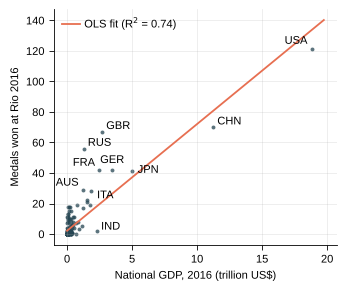

{'r2': np.float64(0.7448861518799129),
 'cv_r2': 0.650296786352048,
 'slope_per_tn': np.float64(6.990559991028144),
 'n': 198}

In [12]:
NOC2ISO = {
    "ALG": "DZA", "ANG": "AGO", "ANT": "ATG", "ARU": "ABW", "ASA": "ASM", "BAH": "BHS",
    "BAN": "BGD", "BAR": "BRB", "BER": "BMU", "BHU": "BTN", "BIZ": "BLZ", "BOT": "BWA",
    "BRN": "BHR", "BRU": "BRN", "BUL": "BGR", "BUR": "BFA", "CAM": "KHM", "CAY": "CYM",
    "CGO": "COG", "CHA": "TCD", "CHI": "CHL", "CRC": "CRI", "CRO": "HRV", "DEN": "DNK",
    "ESA": "SLV", "FIJ": "FJI", "GAM": "GMB", "GBS": "GNB", "GEQ": "GNQ", "GER": "DEU",
    "GRE": "GRC", "GRN": "GRD", "GUA": "GTM", "GUI": "GIN", "HAI": "HTI", "HON": "HND",
    "INA": "IDN", "IRI": "IRN", "ISV": "VIR", "IVB": "VGB", "KOS": "XKX", "KSA": "SAU",
    "LAT": "LVA", "LBA": "LBY", "LES": "LSO", "LIB": "LBN", "MAD": "MDG", "MAS": "MYS",
    "MAW": "MWI", "MGL": "MNG", "MON": "MCO", "MRI": "MUS", "MTN": "MRT", "MYA": "MMR",
    "NCA": "NIC", "NED": "NLD", "NEP": "NPL", "NGR": "NGA", "NIG": "NER", "OMA": "OMN",
    "PAR": "PRY", "PHI": "PHL", "PLE": "PSE", "POR": "PRT", "PUR": "PRI", "RSA": "ZAF",
    "SAM": "WSM", "SEY": "SYC", "SKN": "KNA", "SLO": "SVN", "SOL": "SLB", "SRI": "LKA",
    "SUD": "SDN", "SUI": "CHE", "TAN": "TZA", "TGA": "TON", "TOG": "TGO", "UAE": "ARE",
    "URU": "URY", "VAN": "VUT", "VIE": "VNM", "VIN": "VCT", "ZAM": "ZMB", "ZIM": "ZWE",
    "AHO": "CUW", "SCG": "SRB", "YUG": "SRB",
}
POST_SOVIET = {
    "ALB", "ARM", "AZE", "BLR", "BIH", "BGR", "HRV", "CZE", "EST", "GEO", "HUN", "KAZ",
    "KGZ", "LVA", "LTU", "MKD", "MDA", "MNE", "POL", "ROU", "RUS", "SRB", "SVK", "SVN",
    "TJK", "TKM", "UKR", "UZB", "XKX",
}
gdp = gdp_raw.set_index(["Country Code", "Year"]).Value
pop = pop_raw.set_index(["Country Code", "Year"]).Value
iso = lambda n: NOC2ISO.get(n, n)


def medal_table(year):
    g = summer[summer.Year == year]
    won = g.dropna(subset=["Medal"]).drop_duplicates(["NOC", "Event", "Medal"])
    return won.groupby("NOC").size(), sorted(g.NOC.unique())


m16, nocs16 = medal_table(2016)
rio = pd.DataFrame({"NOC": nocs16})
rio["medals"] = rio.NOC.map(m16).fillna(0)
rio["gdp_tn"] = [gdp.get((iso(n), 2016), np.nan) / 1e12 for n in rio.NOC]
rio = rio.dropna()
ols = smf.ols("medals ~ gdp_tn", data=rio).fit(cov_type="HC1")
cv = []
for r in range(20):
    pred = np.zeros(len(rio))
    for tr, te in KFold(5, shuffle=True, random_state=r).split(rio):
        pred[te] = smf.ols("medals ~ gdp_tn", data=rio.iloc[tr]).fit().predict(rio.iloc[te])
    cv.append(1 - ((rio.medals - pred) ** 2).sum() / ((rio.medals - rio.medals.mean()) ** 2).sum())
RESULTS["ols_2016"] = {"r2": ols.rsquared, "cv_r2": float(np.mean(cv)), "slope_per_tn": ols.params.gdp_tn, "n": int(ols.nobs)}

fig, ax = plt.subplots(figsize=(COL_W, 2.8))
ax.scatter(rio.gdp_tn, rio.medals, s=8, color="#264653", alpha=0.75, lw=0)
xs = np.linspace(0, rio.gdp_tn.max() * 1.05, 50)
ax.plot(xs, ols.params.Intercept + ols.params.gdp_tn * xs, color="#e76f51", lw=1.3, label=f"OLS fit (R$^2$ = {ols.rsquared:.2f})")
# label offsets (points) chosen so neighbouring labels do not overlap
OFFS = {"FRA": (-3, 3, "right"), "GER": (0, 5, "center"), "JPN": (4, -1, "left"), "AUS": (-3, 3, "right"),
        "ITA": (4, -5, "left"), "GBR": (3, 2, "left"), "RUS": (3, 2, "left"), "CHN": (3, 2, "left"),
        "USA": (-3, 4, "right"), "IND": (3, 1, "left")}
for _, r in rio[(rio.medals >= 25) | (rio.gdp_tn >= 2)].iterrows():
    dx, dy, ha = OFFS.get(r.NOC, (3, 2, "left"))
    ax.annotate(r.NOC, (r.gdp_tn, r.medals), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=ANNOT)
ax.set_xlabel("National GDP, 2016 (trillion US$)"); ax.set_ylabel("Medals won at Rio 2016")
ax.legend(loc="upper left", frameon=False)
save(fig, "sarav8.png")
RESULTS["ols_2016"]

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (18 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


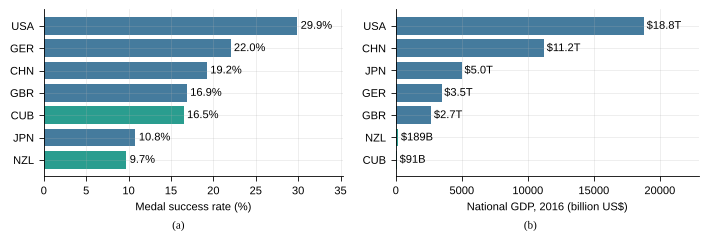

,success_rate,gdp_bn_2016
NOC,,
USA,29.9,18804.9
GER,22.0,3469.9
CHN,19.2,11233.3
GBR,16.9,2689.1
CUB,16.5,91.4
JPN,10.8,5003.7
NZL,9.7,188.9


In [13]:
# Efficiency metrics. Medal success rate = medal rows / athlete-event records (athlete-level), over all
# Summer and Winter Games 1896-2016, the same basis as the decade-level analysis in Section 6.
eff = ath.groupby("NOC").agg(entries=("ID", "size"), medals=("Medal", lambda s: s.notna().sum()))
eff["success_rate"] = eff.medals / eff.entries * 100
eff["gdp_bn_2016"] = [gdp.get((iso(n), 2016), np.nan) / 1e9 for n in eff.index]
COMPARE = ["USA", "GER", "CHN", "GBR", "JPN", "CUB", "NZL"]
SMALL = {"CUB", "NZL"}
table2 = eff.loc[COMPARE, ["success_rate", "gdp_bn_2016"]].sort_values("success_rate", ascending=False)
RESULTS["table2"] = table2.round(1).reset_index().to_dict("records")

fig, axes = panels(2, 2.3)
col = lambda n: "#2a9d8f" if n in SMALL else "#457b9d"
a = table2.sort_values("success_rate")
axes[0].barh(a.index, a.success_rate, color=[col(n) for n in a.index])
for i, v in enumerate(a.success_rate): axes[0].text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=ANNOT)
axes[0].set_xlabel("Medal success rate (%)"); axes[0].set_xlim(0, table2.success_rate.max() * 1.18)
b = table2.sort_values("gdp_bn_2016")
axes[1].barh(b.index, b.gdp_bn_2016, color=[col(n) for n in b.index])
for i, v in enumerate(b.gdp_bn_2016):
    axes[1].text(v + 200, i, f"${v/1000:.1f}T" if v >= 1000 else f"${v:.0f}B", va="center", fontsize=ANNOT)
axes[1].set_xlabel("National GDP, 2016 (billion US$)")
axes[1].set_xlim(0, table2.gdp_bn_2016.max() * 1.22)
save(fig, "sarav9.png")
table2.round(1)

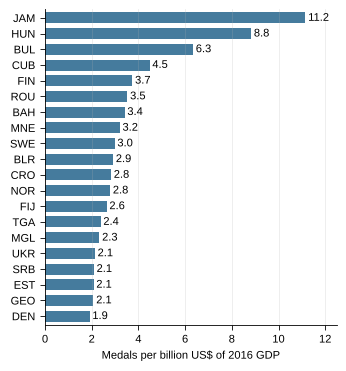

,medals,gdp_bn_2016,roi
NOC,,,
JAM,157,14.08,11.15
HUN,1135,128.61,8.83
BUL,342,53.96,6.34
CUB,409,91.37,4.48
FIN,900,240.77,3.74
ROU,653,185.29,3.52
BAH,40,11.75,3.41
MNE,14,4.38,3.20


In [14]:
# Figure 10: medals (athlete-level, all Games 1896-2016) per billion US$ of 2016 GDP.
# Historical NOCs with no modern successor economy (e.g. Yugoslavia, Soviet Union) have no 2016 GDP and drop out.
HISTORICAL = {"YUG", "SCG", "AHO", "URS", "EUN", "GDR", "FRG", "TCH", "BOH", "ANZ", "RHO", "UAR", "WIF", "YAR", "YMD", "NBO", "NFL", "CRT", "SAA", "IOA", "ROT", "UNK"}
roi = eff.drop(index=[n for n in HISTORICAL if n in eff.index]).dropna(subset=["gdp_bn_2016"])
roi = roi[roi.medals > 0].assign(roi=lambda d: d.medals / d.gdp_bn_2016)
top20 = roi.nlargest(20, "roi").sort_values("roi")
fig, ax = plt.subplots(figsize=(COL_W, 3.6))
ax.barh(top20.index, top20.roi, color="#457b9d", height=0.7)
for i, v in enumerate(top20.roi): ax.text(v + 0.12, i, f"{v:.1f}", va="center", fontsize=ANNOT)
ax.set_xlim(0, top20.roi.max() * 1.12); ax.margins(y=0.01); ax.grid(axis="y", visible=False)
ax.set_xlabel("Medals per billion US$ of 2016 GDP")
save(fig, "sarav10.png")
RESULTS["roi_top"] = roi.nlargest(8, "roi")[["medals", "gdp_bn_2016", "roi"]].round(2).reset_index().to_dict("records")
roi.nlargest(8, "roi")[["medals", "gdp_bn_2016", "roi"]].round(2)

## 6. Efficiency over time (all Summer and Winter Games)
Same success-rate definition, computed per NOC per decade.

In [15]:
def decade_rates(nocs, min_entries):
    out = []
    for c in nocs:
        cd = ath[ath.NOC == c]
        for dec, x in cd.groupby((cd.Year // 10) * 10):
            if len(x) >= min_entries:
                out.append(dict(NOC=c, Decade=dec, rate=x.Medal.notna().mean() * 100))
    return pd.DataFrame(out)


# 11a: fixed top-5 vs bottom-5 cohorts
big = ath.NOC.value_counts(); big = big[big >= 500].index
tl = decade_rates(big, 10)
ndec = tl.groupby("NOC").Decade.nunique(); qual = ndec[ndec >= 8].index
overall = tl[tl.NOC.isin(qual)].groupby("NOC").rate.mean().sort_values(ascending=False)
TOP5, BOT5 = list(overall.head(5).index), list(overall.tail(5).index)
top_tr = tl[tl.NOC.isin(TOP5)].groupby("Decade").rate.mean()
bot_tr = tl[tl.NOC.isin(BOT5)].groupby("Decade").rate.mean()
common = sorted(set(top_tr.index) & set(bot_tr.index))
gap = pd.Series({d: top_tr[d] - bot_tr[d] for d in common})
RESULTS["top5_bottom5"] = {"top5": TOP5, "bottom5": BOT5, "n_qualified": len(qual), "gap_mean": gap.mean(),
                           "gap_2010s": gap[2010], "gap_by_decade": gap.round(1).to_dict(),
                           "bottom5_max": bot_tr.max()}
# Figure 11 is drawn after panel (b) is computed, in the next cell
fig11_a = dict(top=top_tr, bot=bot_tr, common=common)
print(RESULTS["top5_bottom5"])

{'top5': ['USA', 'GER', 'NOR', 'PAK', 'NED'], 'bottom5': ['EGY', 'PER', 'ISL', 'COL', 'LUX'], 'n_qualified': 46, 'gap_mean': np.float64(21.360818057721698), 'gap_2010s': np.float64(17.665063902507583), 'gap_by_decade': {1910: 33.6, 1920: 23.7, 1930: 24.4, 1940: 16.8, 1950: 13.9, 1960: 21.8, 1970: 25.9, 1980: 18.9, 1990: 21.3, 2000: 17.1, 2010: 17.7}, 'bottom5_max': np.float64(3.379006188289477)}


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


... (18 outputs left out)

findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.


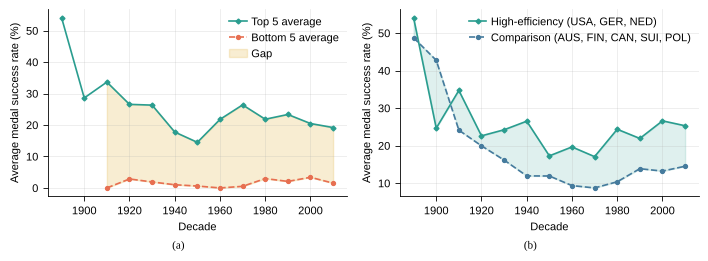

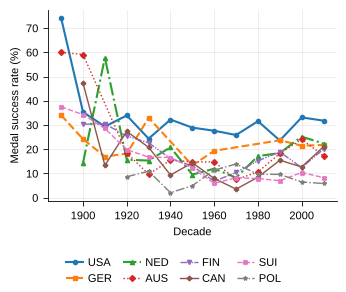

{'high': ['USA', 'GER', 'NED'], 'other': ['AUS', 'FIN', 'CAN', 'SUI', 'POL'], 'gap_2010s': np.float64(10.787176752086623), 'high_range_1920s_on': (np.float64(17.074178776306436), np.float64(26.610663985354023)), 'other_1920s': np.float64(19.959377455380988), 'other_1970s': np.float64(8.739688645651597), 'other_2010s': np.float64(14.519097446949072), 'gap_1920s': np.float64(2.6561581240526912), 'gap_1940s_on_range': (np.float64(5.3618214582157435), np.float64(14.576245679300813)), 'decades_high_leads_since_1910': 11, 'decades_since_1910': 11}


NOC,AUS,CAN,FIN,GER,NED,POL,SUI,USA
Decade,,,,,,,,
1890,60.0,NaN,NaN,34.0,NaN,NaN,37.5,74.1
1900,59.1,47.3,30.4,24.2,14.4,NaN,34.3,35.4
1910,NaN,13.3,30.5,17.0,57.8,NaN,28.6,29.4
1920,18.5,27.4,25.5,18.2,15.7,8.7,19.8,33.9
1930,9.7,20.8,22.7,33.0,15.3,10.9,16.8,24.4
1940,15.5,9.4,16.2,NaN,20.8,2.1,16.6,32.2
1950,14.8,14.4,13.2,13.4,9.5,5.0,12.2,28.9
1960,14.8,7.9,6.8,19.4,12.0,11.4,5.9,27.6
1970,7.5,3.6,10.4,NaN,8.3,13.9,8.3,25.9


In [16]:
# 11b and 12: eight large NOCs selected by recent (1990s-2010s) efficiency
active = list(ath.NOC.value_counts().head(15).index)
tl15 = decade_rates(active, 5)
recent = tl15[tl15.Decade.isin(sorted(tl15.Decade.unique())[-3:])].groupby("NOC").rate.mean().sort_values(ascending=False)
sel8 = list(recent.head(3).index) + list(recent[3:6].index) + list(recent.tail(2).index)
sel8 = [c for c in sel8 if (tl15.NOC == c).sum() >= 5][:8]
HIGH, OTHER = sel8[:3], sel8[3:]
hi_tr = tl15[tl15.NOC.isin(HIGH)].groupby("Decade").rate.mean()
ot_tr = tl15[tl15.NOC.isin(OTHER)].groupby("Decade").rate.mean()
RESULTS["high_vs_other"] = {"high": HIGH, "other": OTHER, "gap_2010s": hi_tr[2010] - ot_tr[2010],
                            "high_range_1920s_on": (hi_tr.loc[1920:].min(), hi_tr.loc[1920:].max()),
                            "other_1920s": ot_tr[1920], "other_1970s": ot_tr[1970], "other_2010s": ot_tr[2010],
                            "gap_1920s": hi_tr[1920] - ot_tr[1920],
                            "gap_1940s_on_range": ((hi_tr - ot_tr).loc[1940:].min(), (hi_tr - ot_tr).loc[1940:].max()),
                            "decades_high_leads_since_1910": int(((hi_tr - ot_tr).loc[1910:] > 0).sum()),
                            "decades_since_1910": int((hi_tr - ot_tr).loc[1910:].notna().sum())}
# Figure 11: (a) fixed top-5 vs bottom-5 cohorts, (b) high-efficiency vs comparison NOCs
fig, axes = panels(2, 2.5)
ax = axes[0]; A = fig11_a
ax.plot(A["top"].index, A["top"].values, "-D", ms=2.5, color="#2a9d8f", label="Top 5 average")
ax.plot(A["bot"].index, A["bot"].values, "--o", ms=2.8, lw=1.2, color="#e76f51", label="Bottom 5 average")
ax.fill_between(A["common"], [A["top"][d] for d in A["common"]], [A["bot"][d] for d in A["common"]], color="#e9c46a", alpha=0.3, label="Gap")
ax.set_xlabel("Decade"); ax.set_ylabel("Average medal success rate (%)"); ax.legend(loc="upper right", frameon=False)
ax = axes[1]
ax.plot(hi_tr.index, hi_tr.values, "-D", ms=2.5, color="#2a9d8f", label=f"High-efficiency ({', '.join(HIGH)})")
ax.plot(ot_tr.index, ot_tr.values, "--o", ms=2.8, lw=1.2, color="#457b9d", label=f"Comparison ({', '.join(OTHER)})")
cm = sorted(set(hi_tr.index) & set(ot_tr.index))
ax.fill_between(cm, [hi_tr[d] for d in cm], [ot_tr[d] for d in cm], color="#2a9d8f", alpha=0.15)
ax.set_xlabel("Decade"); ax.set_ylabel("Average medal success rate (%)"); ax.legend(loc="upper right", frameon=False)
save(fig, "sarav11.png")

# Figure 12: individual trajectories
fig, ax = plt.subplots(figsize=(COL_W, 2.8))
for (mk, ls), c in zip(STYLES, sel8):
    s = tl15[tl15.NOC == c].sort_values("Decade")
    ax.plot(s.Decade, s.rate, marker=mk, ls=ls, lw=1.5 if c in HIGH else 1.0, ms=3, label=c)
ax.set_xlabel("Decade"); ax.set_ylabel("Medal success rate (%)")
fig.legend(loc="outside lower center", ncol=4, frameon=False)
save(fig, "sarav12.png")
traj = tl15[tl15.NOC.isin(sel8)].pivot(index="Decade", columns="NOC", values="rate")
RESULTS["trajectories"] = traj.round(1).to_dict()
print(RESULTS["high_vs_other"]); traj.round(1)

## 7. Multivariate model of medal counts (Summer Games 1996-2016)
Negative binomial regression of medal-table counts on log GDP, log population, host status and
post-Soviet / Eastern Bloc history, with Games fixed effects and standard errors clustered by NOC.

In [17]:
GAMES = {1996: "USA", 2000: "AUS", 2004: "GRE", 2008: "CHN", 2012: "GBR", 2016: "BRA"}
rows = []
for year, host in GAMES.items():
    med, nocs = medal_table(year)
    prev, _ = medal_table(year - 4)
    for n in nocs:
        rows.append(dict(NOC=n, Year=year, medals=int(med.get(n, 0)), medals_prev=int(prev.get(n, 0)),
                         host=int(n == host), post_soviet=int(iso(n) in POST_SOVIET),
                         gdp_usd=gdp.get((iso(n), year), np.nan), pop=pop.get((iso(n), year), np.nan)))
panel = pd.DataFrame(rows)
n_missing = int((panel.gdp_usd.isna() | panel["pop"].isna()).sum())
panel = panel.dropna().reset_index(drop=True)
panel["log_gdp"], panel["log_pop"] = np.log(panel.gdp_usd), np.log(panel["pop"])
panel["log_med_prev"] = np.log1p(panel.medals_prev)
SPECS = {"NB1": "medals ~ log_gdp + C(Year)",
         "NB2": "medals ~ log_gdp + log_pop + host + post_soviet + C(Year)",
         "NB3": "medals ~ log_gdp + log_pop + host + post_soviet + log_med_prev + C(Year)"}


def fit_nb(f, d, cluster=True):
    m = smf.negativebinomial(f, data=d)
    kw = dict(cov_type="cluster", cov_kwds={"groups": d.NOC.astype("category").cat.codes}) if cluster else {}
    return m.fit(disp=0, maxiter=1000, **kw)


def cv_r2(f):
    pred = np.zeros(len(panel))
    for tr, te in GroupKFold(5).split(panel, groups=panel.NOC):
        pred[te] = fit_nb(f, panel.iloc[tr], cluster=False).predict(panel.iloc[te])
    return np.corrcoef(panel.medals, pred)[0, 1] ** 2


nb = {k: fit_nb(f, panel) for k, f in SPECS.items()}
VARS = ["log_gdp", "log_pop", "host", "post_soviet", "log_med_prev"]
table3 = pd.DataFrame({k: {**{v: (f"{m.params[v]:.3f}{'***' if m.pvalues[v] < .001 else '**' if m.pvalues[v] < .01 else '*' if m.pvalues[v] < .05 else ''} ({m.bse[v]:.3f})" if v in m.params else "") for v in VARS},
                           "alpha": f"{m.params['alpha']:.2f}", "AIC": f"{m.aic:,.1f}",
                           "pseudo_R2": f"{m.prsquared:.3f}", "CV_R2": f"{cv_r2(SPECS[k]):.3f}"} for k, m in nb.items()})
lr_stat = 2 * (nb["NB2"].llf - nb["NB1"].llf)
RESULTS["nb"] = {"n_obs": len(panel), "n_nocs": panel.NOC.nunique(), "n_missing": n_missing,
                 "lr_chi2": lr_stat, "lr_p": stats.chi2.sf(lr_stat, 3),
                 "irr": {k: {v: float(np.exp(m.params[v])) for v in VARS if v in m.params} for k, m in nb.items()},
                 "p": {k: {v: float(m.pvalues[v]) for v in VARS if v in m.params} for k, m in nb.items()},
                 "coef": {k: {v: float(m.params[v]) for v in VARS if v in m.params} for k, m in nb.items()},
                 "table3": table3.to_dict()}
print(f"n = {len(panel)} NOC-Games, {panel.NOC.nunique()} NOCs; LR test NB2 vs NB1: chi2(3) = {lr_stat:.1f}")
table3

n = 1162 NOC-Games, 201 NOCs; LR test NB2 vs NB1: chi2(3) = 207.1


,NB1,NB2,NB3
log_gdp,0.747*** (0.045),0.735*** (0.084),0.307*** (0.071)
log_pop,,0.072 (0.106),0.062 (0.052)
host,,0.904*** (0.236),0.148 (0.199)
post_soviet,,1.648*** (0.264),1.099*** (0.170)
log_med_prev,,,0.919*** (0.096)
alpha,2.22,1.42,0.40
AIC,"3,973.0","3,771.9","3,239.5"
pseudo_R2,0.145,0.189,0.305
CV_R2,0.610,0.654,0.746


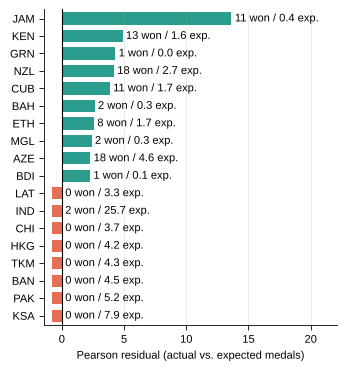

,NOC,medals,expected,resid
1064,KSA,0,7.89,-0.80
1103,PAK,0,5.23,-0.79
978,BAN,0,4.52,-0.78
1143,TKM,0,4.30,-0.78
1043,HKG,0,4.16,-0.78
1001,CHI,0,3.69,-0.77
1047,IND,2,25.73,-0.76
1066,LAT,0,3.28,-0.76
980,BDI,1,0.13,2.27
976,AZE,18,4.59,2.28


In [18]:
# Figure 13: Rio 2016 over- and underperformers relative to NB2
one = panel[panel.Year == 2016].copy()
m2 = nb["NB2"]; alpha = m2.params["alpha"]
one["expected"] = m2.predict(one)
one["resid"] = (one.medals - one.expected) / np.sqrt(one.expected + alpha * one.expected ** 2)
res = one.sort_values("resid", ascending=False)
show = pd.concat([res.head(10), res[res.expected >= 3].tail(8)]).drop_duplicates("NOC").sort_values("resid")
fig, ax = plt.subplots(figsize=(COL_W, 3.6))
ax.barh(show.NOC, show.resid, height=0.7, color=["#2a9d8f" if v > 0 else "#e76f51" for v in show.resid])
pad = show.resid.abs().max() * 0.02
for y, (_, r) in enumerate(show.iterrows()):
    # labels sit to the right of each bar; for negative bars, to the right of zero
    ax.text(max(r.resid, 0) + pad, y, f"{r.medals:.0f} won / {r.expected:.1f} exp.", va="center", ha="left", fontsize=ANNOT)
ax.axvline(0, color="black", lw=0.8)
lo, hi = show.resid.min(), show.resid.max(); ax.set_xlim(lo - 0.6, hi * 1.62)
ax.margins(y=0.01); ax.grid(axis="y", visible=False)
ax.set_xlabel("Pearson residual (actual vs. expected medals)")
save(fig, "sarav13.png")
RESULTS["residuals_2016"] = res[["NOC", "medals", "expected", "resid"]].round(2).head(10).to_dict("records") + \
                            res[res.expected >= 3][["NOC", "medals", "expected", "resid"]].round(2).tail(8).to_dict("records")
show[["NOC", "medals", "expected", "resid"]].round(2)

## 8. Gender balance by sport category (1960-2016)
Distinct female athletes divided by distinct male athletes, per Summer Games and sport category.

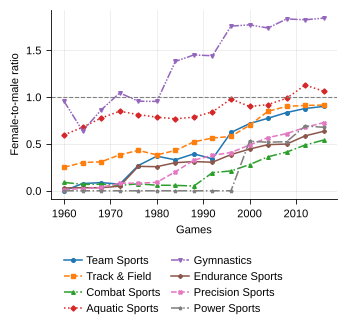

Category names not present in the data: []


cat,Aquatic Sports,Combat Sports,Endurance Sports,Gymnastics,Power Sports,Precision Sports,Team Sports,Track & Field
Year,,,,,,,,
1960,0.60,0.09,0.03,0.95,0.00,0.01,0.00,0.25
1972,0.85,0.06,0.05,1.04,0.00,0.08,0.07,0.38
1992,0.84,0.19,0.30,1.44,0.00,0.38,0.34,0.56
2016,1.06,0.54,0.63,1.84,0.68,0.73,0.90,0.91


In [19]:
CATS = {"Team Sports": ["Basketball", "Football", "Volleyball", "Hockey", "Handball", "Water Polo", "Baseball", "Softball", "Rugby", "Rugby Sevens"],
        "Track & Field": ["Athletics"],
        "Combat Sports": ["Boxing", "Wrestling", "Judo", "Taekwondo", "Fencing"],
        "Aquatic Sports": ["Swimming", "Diving", "Synchronized Swimming"],
        "Gymnastics": ["Gymnastics", "Rhythmic Gymnastics", "Trampolining"],
        "Endurance Sports": ["Cycling", "Rowing", "Canoeing", "Triathlon", "Modern Pentathlon"],
        "Precision Sports": ["Shooting", "Archery", "Equestrianism", "Sailing", "Golf"],
        "Power Sports": ["Weightlifting"]}
s2c = {s: c for c, ss in CATS.items() for s in ss}
missing_sports = sorted(set(s2c) - set(summer.Sport.unique()))
gsub = summer.assign(cat=summer.Sport.map(s2c)).dropna(subset=["cat"])
gsub = gsub[gsub.Year >= 1960]
cnt = gsub.groupby(["Year", "cat", "Sex"]).ID.nunique().unstack(fill_value=0)
ratio = (cnt["F"] / cnt["M"].replace(0, np.nan)).unstack()
fig, ax = plt.subplots(figsize=(COL_W, 3.1))
for (mk, ls), c in zip(STYLES, CATS):
    ax.plot(ratio.index, ratio[c], marker=mk, ls=ls, ms=2.6, lw=1.1, label=c)
ax.axhline(1, ls="--", color="grey", lw=0.8); ax.set_xlabel("Games"); ax.set_ylabel("Female-to-male ratio")
fig.legend(loc="outside lower center", ncol=2, frameon=False)
save(fig, "sarav14.png")
r16 = ratio.loc[2016]
RESULTS["gender"] = {"2016": r16.round(2).to_dict(), "gymnastics_parity_year": int(ratio.Gymnastics[ratio.Gymnastics >= 1].index.min()),
                     "combat_1992": float(ratio["Combat Sports"].get(1992, np.nan)), "combat_2016": float(r16["Combat Sports"]),
                     "categories_within_0.1_of_parity_2016": [c for c in CATS if abs(r16[c] - 1) <= 0.1 or c == "Gymnastics" and r16[c] >= 1]}
print("Category names not present in the data:", missing_sports)
ratio.loc[[1960, 1972, 1992, 2016]].round(2)

## 9. Every number quoted in the paper

In [20]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    return o


with open("paper_numbers.json", "w") as f:
    json.dump(clean(RESULTS), f, indent=1)
print(json.dumps(clean(RESULTS), indent=1)[:6000])

{
 "records_total": 271116,
 "years": [
  1896,
  2016
 ],
 "cluster_n": 85383,
 "silhouette_k5": 0.2842,
 "table1": [
  {
   "archetype": "Lean",
   "share": 31.6,
   "height": 182.7,
   "weight": 77.6,
   "age": 22.4,
   "signature_sports": "Swimming, Football, Canoeing"
  },
  {
   "archetype": "Compact",
   "share": 23.4,
   "height": 168.3,
   "weight": 62.2,
   "age": 23.6,
   "signature_sports": "Gymnastics, Diving, Boxing"
  },
  {
   "archetype": "Mid-career",
   "share": 21.5,
   "height": 178.6,
   "weight": 74.7,
   "age": 29.6,
   "signature_sports": "Modern Pentathlon, Badminton, Fencing"
  },
  {
   "archetype": "Heavyweight",
   "share": 18.3,
   "height": 192.8,
   "weight": 98.2,
   "age": 26.5,
   "signature_sports": "Beach Volleyball, Basketball, Volleyball"
  },
  {
   "archetype": "Veteran",
   "share": 5.2,
   "height": 176.4,
   "weight": 76.7,
   "age": 40.9,
   "signature_sports": "Equestrianism, Shooting, Sailing"
  }
 ],
 "height_range_1960_2016": [
  23.313